# Models Deterministes

Els **models deterministes** tracten el temps com l'única variable explicativa: la sèrie és una funció fixada de *t* més un terme d'error. No incorporen components estocàstiques ni autocorrelació dels residus — això els diferencia dels models estocàstics (SARIMA, ETS) que modelitzen explícitament l'estructura de dependència temporal.

En sèries temporals, els tres deterministes clàssics són:

| Model | Lògica |
|---|---|
| **Mitjana Mòbil (MA_12)** | Previsió = mitjana aritmètica de les últimes 12 observacions. Previsió plana per a tots els horitzons. Referència d'adaptació local sense tendència. |
| **OLS Estacional** | Regressió OLS: tendència lineal (*t*) + 11 dummies de mes. Captura el creixement i el patró estacional però assumeix que ambdós es mantenen constants en el futur. |
| **OLS Complet** | OLS Estacional + dummies d'intervenció (COVID-19, MOVES III). Codifica coneixement de domini: els canvis de règim es representen com variables explicatives observades. |

L'OLS Complet permet contrastar si la incorporació de variables exògenes conegudes millora la predicció respecte del model purament tendencial+estacional.

> **Prerequisit:** executar `data_preparation.ipynb` primer.

In [1]:
import sys
sys.path.insert(0, '../../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path
from sklearn.linear_model import LinearRegression

from features import TECNOLOGIES_MODELITZABLES, COVID_START, COVID_END, MOVES3_START
from evaluation import compute_metrics, walk_forward_cv_full
from plotting import format_ts_ax

DATA_DIR    = Path('../../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../../figures')

plt.rcParams.update({'figure.dpi': 120})
TECNOLOGIES = TECNOLOGIES_MODELITZABLES + ['Total']

In [2]:
pivot_train = pd.read_csv(DATA_DIR / 'pivot_train.csv', index_col='date', parse_dates=True)
pivot_test  = pd.read_csv(DATA_DIR / 'pivot_test.csv',  index_col='date', parse_dates=True)
print(f'Train: {pivot_train.index[0].date()} → {pivot_train.index[-1].date()} ({len(pivot_train)} mesos)')
print(f'Test:  {pivot_test.index[0].date()}  → {pivot_test.index[-1].date()}  ({len(pivot_test)} mesos)')
pivot_train.tail(3)

Train: 2017-01-01 → 2024-12-01 (96 mesos)
Test:  2025-01-01  → 2025-12-01  (12 mesos)


,Diesel Mild Hybrid,Diesel/Elèctric Endollable,Elèctric,Gasolina Mild Hybrid,Gasolina/Elèctric,Gasolina/Elèctric Endollable,Total
date,,,,,,,
2024-10-01,302,23,1266,2090,2783,847,7311
2024-11-01,293,22,1176,1813,2374,652,6330
2024-12-01,352,37,1823,2288,2891,781,8173


## 1. Entrenament i predicció sobre el test set

In [3]:
class MovingAverageForecaster:
    """Previsió = mitjana de les últimes `window` observacions (previsió plana per a tots h)."""

    def __init__(self, window=12):
        self.name   = f'MA_{window}'
        self.window = window

    def fit(self, series):
        self._val = float(np.maximum(series.values[-self.window:].mean(), 0))
        return self

    def predict(self, h):
        return np.full(h, self._val)

    def fit_predict(self, train, h):
        return self.fit(train).predict(h)


class OLSForecaster:
    """
    Regressió OLS determinista:
      Y_t = beta_0 + beta_1*t + sum(beta_i * dummy_mes_i) [+ covid + moves3]

    La variable de tendència t és contínua (0, 1, 2, ...) i s'estén als
    períodes futurs sense discontinuïtat. Les 11 dummies de mes (febrer–desembre)
    capturen l'estacionalitat; gener és la categoria de referència.
    """

    def __init__(self, use_seasonality=True, use_interventions=False, name='OLS'):
        self.use_seasonality   = use_seasonality
        self.use_interventions = use_interventions
        self.name = name

    def _features(self, dates, t_offset=0):
        t    = np.arange(t_offset, t_offset + len(dates), dtype=float).reshape(-1, 1)
        cols = [t]
        if self.use_seasonality:
            m = pd.to_datetime(dates).month
            for mi in range(2, 13):  # 11 dummies, ref = gener
                cols.append((m == mi).astype(float).reshape(-1, 1))
        if self.use_interventions:
            d = pd.to_datetime(dates)
            cols.append(((d >= COVID_START) & (d <= COVID_END)).astype(float).reshape(-1, 1))
            cols.append((d >= MOVES3_START).astype(float).reshape(-1, 1))
        return np.hstack(cols)

    def fit(self, series):
        self._n         = len(series)
        self._last_date = pd.to_datetime(series.index[-1])
        X = self._features(series.index, t_offset=0)
        self._reg = LinearRegression().fit(X, series.values)
        return self

    def predict(self, h):
        future = pd.date_range(
            self._last_date + pd.offsets.MonthBegin(1), periods=h, freq='MS'
        )
        X = self._features(future, t_offset=self._n)
        return np.maximum(self._reg.predict(X), 0)

    def fit_predict(self, train, h):
        return self.fit(train).predict(h)


# ---------------------------------------------------------------------------
MODELS = {
    'MA_12':            MovingAverageForecaster(window=12),
    'OLS_Estacional':   OLSForecaster(use_seasonality=True, use_interventions=False,
                                      name='OLS_Estacional'),
    'OLS_Complet':      OLSForecaster(use_seasonality=True, use_interventions=True,
                                      name='OLS_Complet'),
}

H = len(pivot_test)  # 12 mesos

forecast_records = []
metrics_records  = []

for tech in TECNOLOGIES:
    y_train = pivot_train[tech].dropna()
    y_test  = pivot_test[tech].values

    for model_name, model in MODELS.items():
        y_pred = model.fit_predict(y_train, H)

        m = compute_metrics(y_test, y_pred, y_train.values)
        m['Tecnologia'] = tech
        m['Model']      = model_name
        metrics_records.append(m)

        for i, date in enumerate(pivot_test.index):
            forecast_records.append({
                'date': date, 'Tecnologia': tech,
                'Model': model_name, 'predicted': y_pred[i], 'actual': y_test[i]
            })

df_metrics   = pd.DataFrame(metrics_records)
df_forecasts = pd.DataFrame(forecast_records)
print(f'Models entrenats: {len(MODELS)} × {len(TECNOLOGIES)} tecnologies')

Models entrenats: 3 × 7 tecnologies


## 2. Mètriques sobre el test (2025)

In [ ]:
sub = df_metrics[df_metrics['Tecnologia'] != 'Total']
sub_pivot = sub.pivot_table(
    index='Tecnologia', columns='Model',
    values=['RMSE', 'MAPE', 'MASE']
).round(2)
print('Mètriques per sub-tecnologia (6 sèries):')
display(sub_pivot)

tot = df_metrics[df_metrics['Tecnologia'] == 'Total']
tot_pivot = tot.pivot_table(
    index='Tecnologia', columns='Model',
    values=['RMSE', 'MAPE', 'MASE']
).round(2)
print('\nMètriques al Total:')
tot_pivot

In [ ]:
ranking_total = (
    df_metrics[df_metrics['Tecnologia'] == 'Total']
    .set_index('Model')[['RMSE', 'MAE', 'MAPE', 'MASE']]
    .round(2)
    .sort_values('MASE')
)
print('Rànquing dels 3 deterministes sobre la sèrie Total:')
display(ranking_total)
print()
print('Interpretació MASE: >1 = pitjor que SeasonalNaive | <1 = millor')

## 3. Visualització

Per a cada tecnologia: últims 24 mesos d'historial + prediccions dels tres models sobre el test 2025.

- **MA_12** (groc): previsió horitzontal — captura el nivell recent però ignora la tendència creixent.
- **OLS_Estacional** (violeta): línia amb pendent positiu + oscil·lació mensual — el model bàsic determinista.
- **OLS_Complet** (rosa): igual que l'anterior però amb ajust per COVID i MOVES III; visible principalment en els anys 2020–2021.

In [ ]:
from matplotlib.lines import Line2D

# Per-sub-tecnologia (Total ja té figura dedicada: fig_35_deterministic_total.png)
SUB_TECHS = [t for t in TECNOLOGIES if t != 'Total']
colors = {'MA_12': '#e6ab02', 'OLS_Estacional': '#7b3294', 'OLS_Complet': '#d01c8b'}

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes_flat = axes.flatten()

for i, tech in enumerate(SUB_TECHS):
    ax = axes_flat[i]
    y_train_plot   = pivot_train[tech].iloc[-24:]
    y_test_plot    = pivot_test[tech]
    observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
    observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
    ax.plot(observed_dates, observed_vals, color='#2c7bb6', lw=2, zorder=10)
    ax.axvspan(pivot_test.index[0], pivot_test.index[-1], alpha=0.08, color='gray')
    ax.axvline(pivot_test.index[0], color='gray', ls=':', lw=1)

    for model_name, c in colors.items():
        sub = df_forecasts[(df_forecasts['Tecnologia'] == tech) &
                           (df_forecasts['Model'] == model_name)].sort_values('date')
        ax.plot(sub['date'], sub['predicted'], color=c, lw=1.3, ls='--', alpha=0.85)

    rows = df_metrics[df_metrics['Tecnologia'] == tech].sort_values('MASE')
    best = rows.iloc[0]
    ax.set_title(
        f'{tech}\nmillor: {best["Model"]}  RMSE={best["RMSE"]:.0f}  '
        f'MAE={best["MAE"]:.0f}  MAPE={best["MAPE"]:.1f}%  MASE={best["MASE"]:.2f}',
        fontsize=9)
    format_ts_ax(ax)

# Panells no usats (legend al darrer)
for j in range(len(SUB_TECHS), len(axes_flat)):
    axes_flat[j].axis('off')
legend = [Line2D([0], [0], color='#2c7bb6', lw=2, label='Observat')]
for model_name, c in colors.items():
    legend.append(Line2D([0], [0], color=c, lw=1.5, ls='--', label=model_name))
axes_flat[-1].legend(handles=legend, loc='center', fontsize=11)

plt.suptitle('Models Deterministes — Backtesting per sub-tecnologia (test 2025)', fontsize=13, y=1.0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_34_deterministic_per_tech.png', bbox_inches='tight')
plt.show()

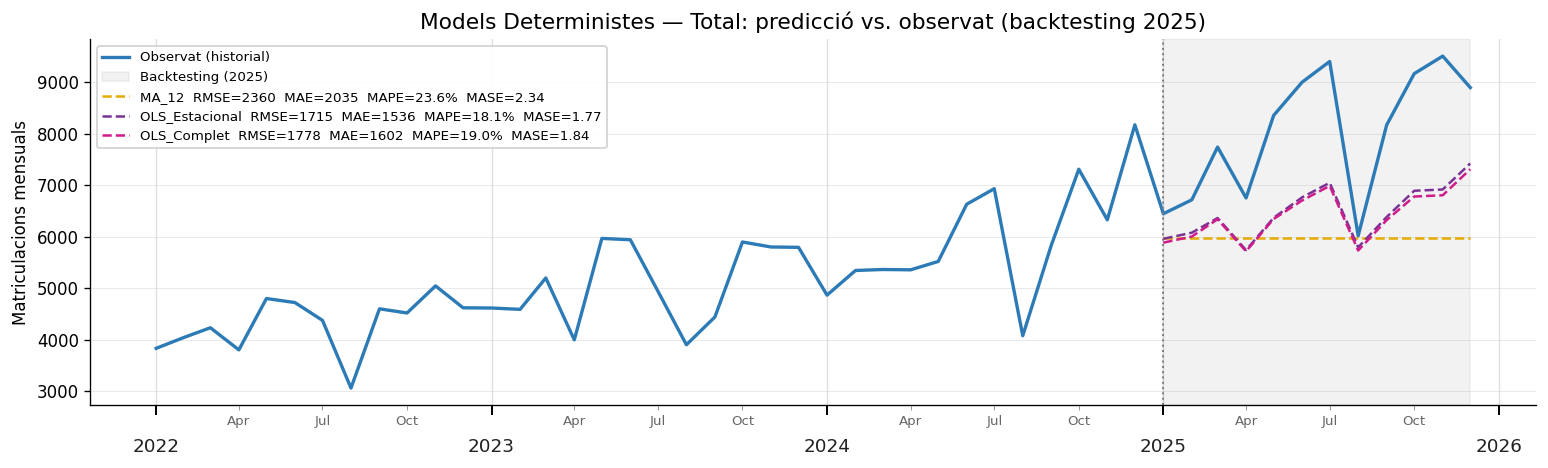

In [7]:
tech = 'Total'
fig, ax = plt.subplots(figsize=(13, 4))

y_train_plot   = pivot_train[tech].iloc[-36:]
y_test_plot    = pivot_test[tech]
observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
ax.plot(observed_dates, observed_vals, color='#2c7bb6', lw=2, label='Observat (historial)')
ax.axvspan(pivot_test.index[0], pivot_test.index[-1], alpha=0.10, color='gray',
           label='Backtesting (2025)')
ax.axvline(pivot_test.index[0], color='gray', ls=':', lw=1.2)

colors_total = {'MA_12': '#e6ab02', 'OLS_Estacional': '#7b3294', 'OLS_Complet': '#d01c8b'}
for model_name, color in colors_total.items():
    sub = df_forecasts[(df_forecasts['Tecnologia'] == tech) &
                       (df_forecasts['Model'] == model_name)].sort_values('date')
    row = df_metrics[(df_metrics['Tecnologia'] == tech) &
                     (df_metrics['Model'] == model_name)].iloc[0]
    label = (f'{model_name}  RMSE={row["RMSE"]:.0f}  MAE={row["MAE"]:.0f}  '
             f'MAPE={row["MAPE"]:.1f}%  MASE={row["MASE"]:.2f}')
    ax.plot(sub['date'], sub['predicted'], color=color, lw=1.5, ls='--', label=label)

ax.set_title(f'Models Deterministes — {tech}: predicció vs. observat (backtesting 2025)',
             fontsize=13)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=8, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_35_deterministic_total.png', bbox_inches='tight')
plt.show()

## 4. Walk-forward validation (rolling-origin)

El backtest sobre 2025 és una sola realització de l'error. Repliquem l'avaluació amb walk-forward: per a cada sèrie, generem origins als mesos 60, 63, ..., 96 (`initial=60`, `step=3`, `horizon=12`) → ~13 folds per sèrie. Les mètriques mitjanes sobre folds tenen molta menys variància que el holdout únic.

En cada fold, l'OLS es re-estima sobre la finestra de train corresponent: els coeficients β canvien fold a fold, de manera que el model s'adapta parcialment als canvis de nivell — però segueix sent determinista (funció fixada de *t*) dins de cada finestra.

In [8]:
pivot_full = pd.concat([pivot_train, pivot_test]).sort_index()

def make_ma_fn(window=12):
    def _fn(train_series):
        m = MovingAverageForecaster(window=window)
        m.fit(train_series)
        return m.predict(12)
    return _fn

def make_ols_fn(use_seasonality=True, use_interventions=False):
    def _fn(train_series):
        m = OLSForecaster(use_seasonality=use_seasonality,
                          use_interventions=use_interventions)
        m.fit(train_series)
        return m.predict(12)
    return _fn

WFV_MODELS = {
    'MA_12':          make_ma_fn(window=12),
    'OLS_Estacional': make_ols_fn(use_seasonality=True, use_interventions=False),
    'OLS_Complet':    make_ols_fn(use_seasonality=True, use_interventions=True),
}

wfv_metric_rows   = []
wfv_forecast_rows = []
print('Walk-forward (initial=60, step=3, horizon=12)...')
for tech in TECNOLOGIES:
    series = pivot_full[tech].dropna()
    for model_name, fn in WFV_MODELS.items():
        m_df, f_df = walk_forward_cv_full(series, fn, initial=60, step=3, horizon=12)
        m_df['Tecnologia'] = tech
        m_df['Model']      = model_name
        f_df['Tecnologia'] = tech
        f_df['Model']      = model_name
        wfv_metric_rows.append(m_df)
        wfv_forecast_rows.append(f_df)
    print(f'  {tech:35s}: ok')

df_wfv_metrics   = pd.concat(wfv_metric_rows,   ignore_index=True)
df_wfv_forecasts = pd.concat(wfv_forecast_rows, ignore_index=True)

wfv_agg = (df_wfv_metrics.dropna(subset=['MASE'])
           .groupby(['Tecnologia', 'Model'])[['RMSE', 'MAE', 'MAPE', 'MASE']]
           .mean().round(2).reset_index())
print('\nMitjana WFV MASE per tecnologia × model:')
display(wfv_agg.pivot(index='Tecnologia', columns='Model', values='MASE').round(2))

Walk-forward (initial=60, step=3, horizon=12)...
  Elèctric                           : ok
  Gasolina Mild Hybrid               : ok
  Gasolina/Elèctric                  : ok
  Gasolina/Elèctric Endollable       : ok
  Diesel Mild Hybrid                 : ok
  Diesel/Elèctric Endollable         : ok
  Total                              : ok

Mitjana WFV MASE per tecnologia × model:


Model,MA_12,OLS_Complet,OLS_Estacional
Tecnologia,,,
Diesel Mild Hybrid,0.60,1.09,1.01
Diesel/Elèctric Endollable,1.51,1.36,1.44
Elèctric,0.77,0.72,0.72
Gasolina Mild Hybrid,1.41,0.84,0.79
Gasolina/Elèctric,1.53,1.45,1.60
Gasolina/Elèctric Endollable,1.70,1.50,1.55
Total,1.35,0.86,0.86


In [ ]:
# Visualització WFV per sub-tecnologia (Total ja analitzat separadament)
SUB_TECHS = [t for t in TECNOLOGIES if t != 'Total']
colors_wfv = {'MA_12': '#e6ab02', 'OLS_Estacional': '#7b3294', 'OLS_Complet': '#d01c8b'}

fig, axes = plt.subplots(4, 2, figsize=(14, 18))
axes_flat = axes.flatten()

for i, tech in enumerate(SUB_TECHS):
    ax = axes_flat[i]
    s = pivot_full[tech]
    ax.plot(s.index, s.values, color='#2c7bb6', lw=2, zorder=10)

    for model_name, c in colors_wfv.items():
        sub = df_wfv_forecasts[
            (df_wfv_forecasts['Tecnologia'] == tech)
            & (df_wfv_forecasts['Model'] == model_name)
            & (df_wfv_forecasts['h'] == 1)
        ].sort_values('date')
        ax.plot(pd.to_datetime(sub['date']), sub['predicted'],
                color=c, lw=1.5, ls='--', marker='o', ms=4, alpha=0.85)

    rows = wfv_agg[wfv_agg['Tecnologia'] == tech].sort_values('MASE')
    if len(rows):
        best = rows.iloc[0]
        ax.set_title(
            f'{tech}\nmillor WFV: {best["Model"]}  RMSE={best["RMSE"]:.0f}  '
            f'MAE={best["MAE"]:.0f}  MAPE={best["MAPE"]:.1f}%  MASE={best["MASE"]:.2f}',
            fontsize=9)
    format_ts_ax(ax)

for j in range(len(SUB_TECHS), len(axes_flat)):
    axes_flat[j].axis('off')
legend = [Line2D([0], [0], color='#2c7bb6', lw=2, label='Observat')]
for model_name, c in colors_wfv.items():
    legend.append(Line2D([0], [0], color=c, lw=1.5, ls='--',
                         marker='o', ms=4, label=model_name))
axes_flat[-1].legend(handles=legend, loc='center', fontsize=11,
                     title='predicció h=1 per fold')

plt.suptitle('Models Deterministes — Walk-forward per sub-tecnologia (13 folds, h=1)',
             fontsize=13, y=1.0)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_36_deterministic_wfv_per_tech.png', bbox_inches='tight')
plt.show()

## 5. Discussió i comparació amb models estocàstics

Els models deterministes estableixen un **sostre inferior de complexitat**: expliquen el que es pot explicar amb una funció lineal de *t* i variables de calendari conegudes.

**Punts forts:**
- Alta interpretabilitat: els coeficients β quantifiquen l'efecte de cada variable (tendència mensual, estacionalitat, COVID, MOVES III).
- Adequats per a sèries amb tendència lineal estable i estacionalitat constant.
- OLS_Complet permet incorporar dummies d'intervenció futures conegudes (ex. nova convocatòria MOVES).

**Limitacions respecte als models estocàstics:**
- **La tendència lineal és rígida:** si el creixement accelera (Elèctric, Gas/Elèctric Endollable), l'OLS subestima sistemàticament el nivell.
- **L'estacionalitat és fixa:** no s'adapta a canvis en el patró (ex. efectes de les polítiques d'incentiu sobre mesos concrets).
- **Els residus estan autocorrelacionats:** l'OLS assumeix errors independents, però en sèries temporals els residus hereten l'estructura ARMA de la sèrie. Això no invalida les prediccions però fa que els intervals de confiança OLS siguin incorrectes (massa estrets).
- **MA_12 ignora la tendència:** útil com a referència d'adaptació local però inadequat per a sèries en creixement.

En conclusió, els models estocàstics (SARIMA, ETS) superen els deterministes perquè modelitzen explícitament la dinàmica dels residus i permeten actualitzar el nivell i la tendència de forma adaptativa. Per a sèries amb ruptures estructurals (Gas/Elèctric Endollable, +101% el 2024→2025), ni els deterministes ni els estocàstics univariants són suficients: calen variables exògenes o models ML.

## 6. Guardar resultats

In [10]:
df_forecasts.to_csv(RESULTS_DIR / 'deterministic_forecasts.csv', index=False)
df_metrics.to_csv(RESULTS_DIR / 'deterministic_metrics.csv', index=False)
df_wfv_metrics.to_csv(RESULTS_DIR / 'deterministic_wfv_metrics.csv', index=False)
df_wfv_forecasts.to_csv(RESULTS_DIR / 'deterministic_wfv_forecasts.csv', index=False)
print('Guardats:')
print('  deterministic_forecasts.csv, deterministic_metrics.csv')
print('  deterministic_wfv_metrics.csv, deterministic_wfv_forecasts.csv')

Guardats:
  deterministic_forecasts.csv, deterministic_metrics.csv
  deterministic_wfv_metrics.csv, deterministic_wfv_forecasts.csv
